<a href="https://colab.research.google.com/github/luciusartor1uscastus/python-practice-algos/blob/master/hw_7_borisov_f_o.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q umap-learn


До PCA: 30 фичей, точность 0.9649
После PCA: 10 фичей, точность 0.9474
Разница: -0.0175


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


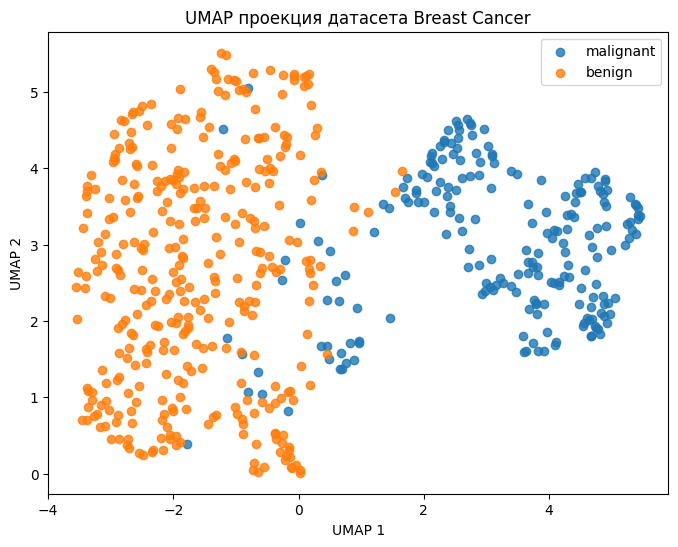

In [2]:

import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score
import umap

data = load_breast_cancer()
X, y = data.data, data.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

rf_orig = RandomForestClassifier(random_state=42)
rf_orig.fit(X_train, y_train)
acc_orig = accuracy_score(y_test, rf_orig.predict(X_test))

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

pca = PCA(n_components=0.95, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

rf_pca = RandomForestClassifier(random_state=42)
rf_pca.fit(X_train_pca, y_train)
acc_pca = accuracy_score(y_test, rf_pca.predict(X_test_pca))

print(f"До PCA: {X.shape[1]} фичей, точность {acc_orig:.4f}")
print(f"После PCA: {X_train_pca.shape[1]} фичей, точность {acc_pca:.4f}")
print(f"Разница: {acc_pca - acc_orig:+.4f}")

X_all_scaled = scaler.fit_transform(X)
reducer = umap.UMAP(random_state=42)
embedding = reducer.fit_transform(X_all_scaled)

plt.figure(figsize=(8, 6))
for target_val, target_name in enumerate(data.target_names):
    idx = y == target_val
    plt.scatter(embedding[idx, 0], embedding[idx, 1], label=target_name, alpha=0.8)

plt.title("UMAP проекция датасета Breast Cancer")
plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.legend()
plt.show()